# IPL 2025 Player Analysis



1. Import pandas and numpy
2. Load datasets
3. Display top 5 records of both dataframes (bat_df and bowl_df)
4. Display dimensions of dataset using shape and columns keyword
5. Check for missing values
6. Display top 10 batsman (sort by runs)
7. Display top 10 bowlers  (sort by wkt)
8. Calculate Runs scored only by 4's and 6's
9. Filter Bowlers with Good Economy(ECO<7) and Strike Rate(SR<20)
10. Merge bat_df and bowl_df
11. Display all rounder player with runs > 200 and wkt >10


In [ ]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Load the datasets

bat_df=pd.read_csv(r"IPL_2025\IPL2025Batters.csv")
bowl_df=pd.read_csv(r"IPL_2025/IPL2025Bowlers.csv")

# Preview Data
print(bat_df.head())
print(bowl_df.head())

         Player Name Team  Runs  Matches  Inn  No    HS    AVG   BF      SR  \
0      Sai Sudharsan   GT   759       15   15   1  108*  54.21  486  156.17   
1  Surya Kumar Yadav   MI   717       16   16   5   73*  65.18  427  167.91   
2        Virat Kohli  RCB   657       15   15   3   73*  54.75  454  144.71   
3       Shubman Gill   GT   650       15   15   2   93*  50.00  417  155.87   
4     Mitchell Marsh  LSG   627       13   13   0   117  48.23  383  163.70   

   100s  50s  4s  6s  
0     1    6  88  21  
1     0    5  69  38  
2     0    8  66  19  
3     0    6  62  24  
4     1    6  56  37  
       Player Name  Team  WKT  MAT  INN   OVR  RUNS   BBI    AVG   ECO     SR  \
0  Prasidh Krishna    GT   25   15   15  59.0   488  41/4  19.52  8.27  14.16   
1       Noor Ahmad   CSK   24   14   14  50.0   408  18/4  17.00  8.16  12.50   
2   Josh Hazlewood   RCB   22   12   12  44.0   386  33/4  17.54  8.77  12.00   
3      Trent Boult    MI   22   16   16  57.4   517  26/4  23.5

## Dataset Overview

In [ ]:
# Display shapes and column names
print("Batting Data Shape:", )
print("Bowling Data Shape:",)
print("Batting Columns:",)
print("Bowling Columns:",)

In [2]:
# Check for missing values
bat_df.isnull().sum()

# Data types
for i in bat_df:
    print(i,bat_df[i].dtype)

Player Name object
Team object
Runs int64
Matches int64
Inn int64
No int64
HS object
AVG object
BF int64
SR float64
100s int64
50s int64
4s int64
6s int64


##  Batting Analysis

In [6]:
# Top 10 Run Scorers
top_batters=bat_df.sort_values(by='Runs',ascending=False)
top_batters.head(10)

,Player Name,Team,Runs,Matches,Inn,No,HS,AVG,BF,SR,100s,50s,4s,6s
0,Sai Sudharsan,GT,759,15,15,1,108*,54.21,486,156.17,1,6,88,21
1,Surya Kumar Yadav,MI,717,16,16,5,73*,65.18,427,167.91,0,5,69,38
2,Virat Kohli,RCB,657,15,15,3,73*,54.75,454,144.71,0,8,66,19
3,Shubman Gill,GT,650,15,15,2,93*,50.00,417,155.87,0,6,62,24
4,Mitchell Marsh,LSG,627,13,13,0,117,48.23,383,163.70,1,6,56,37
5,Shreyas Iyer,PBKS,604,17,17,5,97*,50.33,345,175.07,0,6,43,39
6,Yashasvi Jaiswal,RR,559,14,14,1,75,43.00,350,159.71,0,6,60,28
7,Prabhsimran Singh,PBKS,549,17,17,0,91,32.29,342,160.52,0,4,56,30
8,K L Rahul,DC,539,13,13,3,112*,53.90,360,149.72,1,3,52,21
9,Jos Buttler,GT,538,14,13,4,97*,59.78,330,163.03,0,5,52,24


In [7]:
# Create BoundaryRuns column
bat_df['BoundaryRuns']=bat_df['4s']*4 + bat_df['6s']*6

In [8]:
bat_df

,Player Name,Team,Runs,Matches,Inn,No,HS,AVG,BF,SR,100s,50s,4s,6s,BoundaryRuns
0,Sai Sudharsan,GT,759,15,15,1,108*,54.21,486,156.17,1,6,88,21,478
1,Surya Kumar Yadav,MI,717,16,16,5,73*,65.18,427,167.91,0,5,69,38,504
2,Virat Kohli,RCB,657,15,15,3,73*,54.75,454,144.71,0,8,66,19,378
3,Shubman Gill,GT,650,15,15,2,93*,50.00,417,155.87,0,6,62,24,392
4,Mitchell Marsh,LSG,627,13,13,0,117,48.23,383,163.70,1,6,56,37,446
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
151,Khaleel Ahmed,CSK,1,14,2,2,1*,-,2,50.00,0,0,0,0,0
152,Mohit Sharma,DC,1,8,2,1,1*,1.00,3,33.33,0,0,0,0,0
153,Donovan Ferreira,DC,1,1,1,0,1,1.00,3,33.33,0,0,0,0,0
154,Digvesh Singh,LSG,1,13,2,1,1,1.00,3,33.33,0,0,0,0,0


In [9]:
# Statistical Calculations Descriptive Analysis (Runs)
bat_df['Runs'].describe()

,Runs
count,156.000000
mean,161.320513
std,180.352772
min,1.000000
25%,10.750000
50%,93.500000
75%,254.250000
max,759.000000


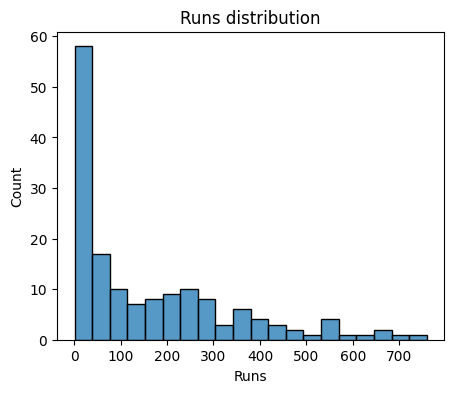

In [14]:
# Histplot
plt.figure(figsize=(5,4))
sns.histplot(data=bat_df,x='Runs',bins=20)
plt.title('Runs distribution')
plt.show()

In [16]:
# High Strike Rate and 6s Filter ( strike rate > 150 and 6's > 30)
bat_df[(bat_df['SR']>150) & (bat_df['6s']>30)]

,Player Name,Team,Runs,Matches,Inn,No,HS,AVG,BF,SR,100s,50s,4s,6s,BoundaryRuns
1,Surya Kumar Yadav,MI,717,16,16,5,73*,65.18,427,167.91,0,5,69,38,504
4,Mitchell Marsh,LSG,627,13,13,0,117,48.23,383,163.70,1,6,56,37,446
5,Shreyas Iyer,PBKS,604,17,17,5,97*,50.33,345,175.07,0,6,43,39,406
10,Nicholas Pooran,LSG,524,14,14,2,87*,43.67,267,196.25,0,5,45,40,420


In [61]:
# top 3 best batsman
bat_df[(bat_df['SR']>150) & (bat_df['Runs']>500)].head(3)

,Player Name,Team,Runs,Matches,Inn,No,HS,AVG,BF,SR,100s,50s,4s,6s,BoundaryRuns
0,Sai Sudharsan,GT,759,15,15,1,108*,54.21,486,156.17,1,6,88,21,478
1,Surya Kumar Yadav,MI,717,16,16,5,73*,65.18,427,167.91,0,5,69,38,504
3,Shubman Gill,GT,650,15,15,2,93*,50.00,417,155.87,0,6,62,24,392


## Bowling Analysis

In [17]:
bowl_df.columns

Index(['Player Name', 'Team', 'WKT', 'MAT', 'INN', 'OVR', 'RUNS', 'BBI', 'AVG',
       'ECO', 'SR', '4W', '5W'],
      dtype='object')

In [19]:
# Top 10 Wicket Takers

top_Wicket_takers=bowl_df.sort_values(by='WKT',ascending=False)
top_Wicket_takers.head(10)

,Player Name,Team,WKT,MAT,INN,OVR,RUNS,BBI,AVG,ECO,SR,4W,5W
0,Prasidh Krishna,GT,25,15,15,59.0,488,41/4,19.52,8.27,14.16,1,0
1,Noor Ahmad,CSK,24,14,14,50.0,408,18/4,17.00,8.16,12.50,2,0
2,Josh Hazlewood,RCB,22,12,12,44.0,386,33/4,17.54,8.77,12.00,1,0
3,Trent Boult,MI,22,16,16,57.4,517,26/4,23.50,8.96,15.72,1,0
4,Arshdeep Singh,PBKS,21,17,16,58.2,518,16/3,24.66,8.88,16.66,0,0
5,Sai Kishore,GT,19,15,15,42.3,393,30/3,20.68,9.24,13.42,0,0
6,Jasprit Bumrah,MI,18,12,12,47.2,316,22/4,17.55,6.67,15.77,1,0
7,Varun Chakaravarthy,KKR,17,13,13,50.0,383,22/3,22.52,7.66,17.64,0,0
8,Krunal Pandya,RCB,17,15,15,46.0,379,45/4,22.29,8.23,16.23,1,0
9,Bhuvneshwar Kumar,RCB,17,14,14,52.0,483,33/3,28.41,9.28,18.35,0,0


In [21]:
# Statistical Calculations descriptive analysis  (Economy mean,max wickets, average median)
bowl_df[['ECO','WKT']].describe()


,ECO,WKT
count,108.000000,108.000000
mean,9.875093,7.675926
std,1.592371,6.294678
min,6.500000,1.000000
25%,8.822500,2.000000
50%,9.705000,6.000000
75%,10.937500,12.250000
max,14.100000,25.000000


In [23]:
print("Average Economy=",bowl_df['ECO'].mean())
print("Max Economy=",bowl_df['ECO'].max())

Average Economy= 9.875092592592592
Max Economy= 14.1


In [25]:
# Filter Bowlers with Good Economy and Strike Rate  economy < 7 and strike rate < 20
bowl_df[(bowl_df['ECO']<7) & (bowl_df['SR']<20)]

,Player Name,Team,WKT,MAT,INN,OVR,RUNS,BBI,AVG,ECO,SR,4W,5W
6,Jasprit Bumrah,MI,18,12,12,47.2,316,22/4,17.55,6.67,15.77,1,0


## Combined Analysis

Teams

In [46]:
# Merge Batting and Bowling Data

All_Player_df= pd.merge(bat_df,bowl_df,how='outer',on='Player Name')

All_Player_df.columns

Index(['Player Name', 'Team_x', 'Runs', 'Matches', 'Inn', 'No', 'HS', 'AVG_x',
       'BF', 'SR_x', '100s', '50s', '4s', '6s', 'BoundaryRuns', 'Team_y',
       'WKT', 'MAT', 'INN', 'OVR', 'RUNS', 'BBI', 'AVG_y', 'ECO', 'SR_y', '4W',
       '5W'],
      dtype='object')

In [50]:
All_Player_df.groupby(by='Team_y').count()

,Player Name,Team_x,Runs,Matches,Inn,No,HS,AVG_x,BF,SR_x,...,MAT,INN,OVR,RUNS,BBI,AVG_y,ECO,SR_y,4W,5W
Team_y,,,,,,,,,,,,,,,,,,,,,
CSK,9,6,6,6,6,6,6,6,6,6,...,9,9,9,9,9,9,9,9,9,9
DC,8,6,6,6,6,6,6,6,6,6,...,8,8,8,8,8,8,8,8,8,8
GT,11,8,8,8,8,8,8,8,8,8,...,11,11,11,11,11,11,11,11,11,11
KKR,9,6,6,6,6,6,6,6,6,6,...,9,9,9,9,9,9,9,9,9,9
LSG,13,9,9,9,9,9,9,9,9,9,...,13,13,13,13,13,13,13,13,13,13
MI,13,8,8,8,8,8,8,8,8,8,...,13,13,13,13,13,13,13,13,13,13
PBKS,14,8,8,8,8,8,8,8,8,8,...,14,14,14,14,14,14,14,14,14,14
RCB,10,5,5,5,5,5,5,5,5,5,...,10,10,10,10,10,10,10,10,10,10
RR,10,9,9,9,9,9,9,9,9,9,...,10,10,10,10,10,10,10,10,10,10


In [53]:
bat_df.columns

Index(['Player Name', 'Team', 'Runs', 'Matches', 'Inn', 'No', 'HS', 'AVG',
       'BF', 'SR', '100s', '50s', '4s', '6s', 'BoundaryRuns'],
      dtype='object')

In [54]:
bowl_df.columns

Index(['Player Name', 'Team', 'WKT', 'MAT', 'INN', 'OVR', 'RUNS', 'BBI', 'AVG',
       'ECO', 'SR', '4W', '5W'],
      dtype='object')

In [51]:
# merge dataframes , retrieve common records

All_rounders_df= pd.merge(bat_df,bowl_df,how='inner',on='Player Name')

In [52]:
All_rounders_df

,Player Name,Team_x,Runs,Matches,Inn,No,HS,AVG_x,BF,SR_x,...,MAT,INN,OVR,RUNS,BBI,AVG_y,ECO,SR_y,4W,5W
0,Aiden Markram,LSG,445,13,13,0,66,34.23,299,148.82,...,13,5,11.0,102,30/2,25.50,9.27,16.50,0,0
1,Riyan Parag,RR,393,14,14,2,95,32.75,236,166.52,...,14,9,20.0,170,1-Dec,56.66,8.50,40.00,0,0
2,Ayush Badoni,LSG,329,14,11,1,74,32.90,222,148.19,...,14,2,1.4,13,2-Apr,6.50,7.80,5.00,0,0
3,Ravindra Jadeja,CSK,301,14,14,5,77*,33.44,222,135.58,...,14,14,37.5,324,17/2,32.40,8.56,22.70,0,0
4,Axar Patel,DC,263,12,11,1,43,26.30,167,157.48,...,12,11,34.0,288,19/2,57.60,8.47,40.80,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66,V Satyanarayana Penmetsa,MI,1,2,1,1,1*,-,1,100.00,...,2,2,4.0,53,40/1,53.00,13.25,24.00,0,0
67,Karn Sharma,MI,1,6,1,1,1*,-,1,100.00,...,6,5,15.0,128,23/3,18.28,8.53,12.85,0,0
68,Khaleel Ahmed,CSK,1,14,2,2,1*,-,2,50.00,...,14,14,46.4,447,29/3,29.80,9.57,18.66,0,0
69,Mohit Sharma,DC,1,8,2,1,1*,1.00,3,33.33,...,8,8,25.0,257,1-Oct,128.50,10.28,75.00,0,0


In [55]:
# Identify All-rounders (Runs > 200, wickets >10)
All_rounders_df[(All_rounders_df['Runs']>200) & (All_rounders_df['WKT']>10)]

,Player Name,Team_x,Runs,Matches,Inn,No,HS,AVG_x,BF,SR_x,...,MAT,INN,OVR,RUNS,BBI,AVG_y,ECO,SR_y,4W,5W
5,Sunil Narine,KKR,246,12,12,1,44,22.36,144,170.83,...,12,12,45.0,351,13/3,29.25,7.80,22.5,0,0
7,Hardik Pandya,MI,224,15,12,3,48*,24.89,137,163.50,...,15,14,35.0,342,36/5,24.42,9.77,15.0,0,1


In [ ]:
# All-rounder Score  (Max runs, max wickets)


In [57]:
# Purple Cap ( Highest Wickets in tournament)
bowl_df.sort_values(by='WKT',ascending=False).head(1)

,Player Name,Team,WKT,MAT,INN,OVR,RUNS,BBI,AVG,ECO,SR,4W,5W
0,Prasidh Krishna,GT,25,15,15,59.0,488,41/4,19.52,8.27,14.16,1,0


In [58]:
# Orange Cap
bat_df.sort_values(by='Runs', ascending=False).head(1)

,Player Name,Team,Runs,Matches,Inn,No,HS,AVG,BF,SR,100s,50s,4s,6s,BoundaryRuns
0,Sai Sudharsan,GT,759,15,15,1,108*,54.21,486,156.17,1,6,88,21,478


Insights
1. Best All rounder players are Sunil Narine and Hardik Pandya <br>
2. Best Batsman Sai Sudarshan
3. Best Bowler Bumrah
4. Orange Cap Player Sai Sudharshan
5. Purple Cap Prasidh Krishna

In [62]:
# export to csv
All_rounders_df.to_csv('IPL_AllRounders.csv')